# World Model Pipeline

This notebook demonstrates the complete pipeline for both world-model training modes.

## WM Mode (Sections 1–4) — monolithic `WorldModel`
1. **Data Loading** — local NPZ or Hugging Face Hub trajectories
2. **Architecture** — DINOv2/CNN backbone + MLP/RSSM dynamics + state_head + risk_head
3. **Training** — multi-step rollout loss (pose MSE + collision BCE)
4. **Inference & MPC** — CEM planning in latent space

## DINO-WM Mode (Section 5) — modular `WM` class
| Sub-section | `predictor_type` | `state_dim` | Highlights |
|---|---|---|---|
| **5A** — trial.yaml baseline | `"vit"` | `0` | Patch-level JEPA, per-component LRs |
| **5B** — research config | `"vit"` | `0` | AMP · EMA target encoder · cosine LR · grad accum |
| **5C** — checkpoints | `"vit"` | `0` | Inspect / resume saved runs |
| **5D** — MLP predictor | `"mlp"` | `0` | Frame-level residual dynamics, ~100× lighter |
| **5E** — RSSM predictor | `"rssm"` | `0` | Recurrent GRU dynamics, partial observability |
| **5F** — state/risk supervision | `"vit"` | `6` | Pose MSE + collision BCE auxiliary heads |
| **5G** — full combo | `"rssm"` | `6` | RSSM + all auxiliary losses |
| **5H** — cheat-sheet | — | — | Quick reference for all modes |

In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Ensure project root is in path
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '../..'))
sys.path.append(os.path.join(PROJECT_ROOT, 'src'))

from world_model.data import NPZEpisodeDataset, HFWindowDataset, collate_npz, collate_hf
from world_model.architecture import WorldModel
from world_model.engine.trainer import TrainConfig, rollout_loss
from world_model.mpc import cem_plan, CEMConfig

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## 1. Data Loading

The world model can load data from two main sources:
- **Local NPZ Episodes**: Trajectories stored as individual `.npz` files.
- **Hugging Face Hub**: Trajectories hosted as Arrow/Parquet datasets.

### B. Hugging Face Dataloading

Loading lquan9/collect1...
[HFWindowDataset] Attempting to load from Hub: lquan9/collect1
Total segments (windows/episodes): 1032
Total frames in dataset: 51600
Columns: ['episode_id', 'frame_idx', 'image', 'odom_0', 'odom_1', 'odom_2', 'odom_3', 'odom_4', 'odom_5', 'odom_6', 'odom_7', 'odom_8', 'odom_9', 'odom_10', 'odom_11', 'odom_12', 'action_0', 'action_1', 'action_2', 'action_3', 'action_4', 'action_5', 'action_6', 'action_7', 'action_8', 'action_9', 'action_10', 'action_11', 'action_12', 'imu_0', 'imu_1', 'imu_2', 'imu_3', 'imu_4', 'imu_5', 'imu_6', 'imu_7', 'imu_8', 'imu_9', 'depth_mean']
Dimensions: Odom=13, IMU=10, Act=13
[HFWindowDataset] __getitem__ idx=0 wid=0 n_frames=50
  row_indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]...
  batch_data keys: ['episode_id', 'frame_idx', 'image', 'odom_0', 'odom_1', 'odom_2', 'odom_3', 'odom_4', 'odom_5', 'odom_6', 'odom_7', 'odom_8', 'odom_9', 'odom_10', 'odom_11', 'odom_12', 'action_0', 'action_1', 'action_2', 'action_3', 'action_4', 'action_5

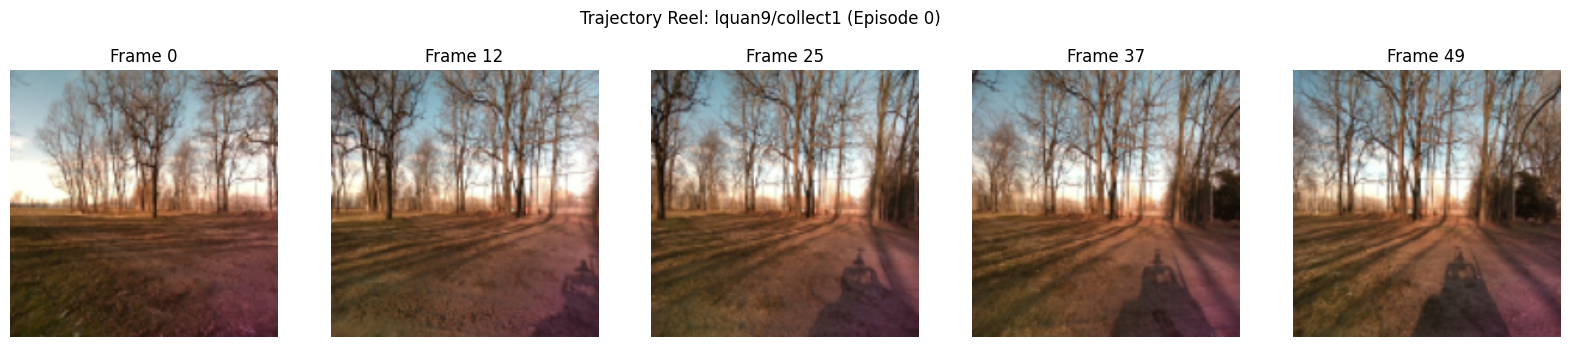

In [2]:
hf_repo = "lquan9/collect1"
ep = 0
try:
    print(f"Loading {hf_repo}...")
    ds_hf = HFWindowDataset(hf_repo, img_size=224)
    
    # Dataset Statistics
    print(f"Total segments (windows/episodes): {len(ds_hf)}")
    print(f"Total frames in dataset: {len(ds_hf._ds)}")
    print(f"Columns: {ds_hf._ds.column_names}")
    print(f"Dimensions: Odom={ds_hf.D_odom}, IMU={ds_hf.D_imu}, Act={ds_hf.D_act}")
    
    window = ds_hf[ep]
    rgb = window["rgb"]
    print(f"\nShowing reel for Episode {ep} \
          (Sequence length: {rgb.shape[0]} frames)")
    
    # Image Reel (show 5 images across the window)
    n_frames = rgb.shape[0]
    indices = [0, n_frames//4, n_frames//2, (3*n_frames)//4, n_frames-1]
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    for i, idx in enumerate(indices):
        # rgb is (T, 3, H, W) numpy array
        img = rgb[idx].transpose(1, 2, 0)
        axes[i].imshow(img)
        axes[i].set_title(f"Frame {idx}")
        axes[i].axis('off')
    plt.suptitle(f"Trajectory Reel: {hf_repo} (Episode {ep})")
    plt.show()
except Exception as e:
    print(f"Error loading dataset: {e}")


## 2. World Model Architecture

The `WorldModel` is modular, consisting of a vision encoder, a proprioception encoder, a fusion layer, and latent dynamics.

In [3]:
o_dim = ds_hf.D_odom
i_dim = ds_hf.D_imu
a_dim = ds_hf.D_act

model = WorldModel(
    odom_dim=o_dim,
    imu_dim=i_dim,
    act_dim=a_dim, 
    backbone='dinov2' 
).to(device)

print(model)

/home/long/PhD/Coursework/Embodied_Learning_and_Vision/Project/Code/ds_ga_3001/external/dino/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/home/long/PhD/Coursework/Embodied_Learning_and_Vision/Project/Code/ds_ga_3001/external/dino/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/home/long/PhD/Coursework/Embodied_Learning_and_Vision/Project/Code/ds_ga_3001/external/dino/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


WorldModel(
  (vision): DINOv2Encoder(
    (model): DinoVisionTransformer(
      (patch_embed): PatchEmbed(
        (proj): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
        (norm): Identity()
      )
      (blocks): ModuleList(
        (0-11): 12 x NestedTensorBlock(
          (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (attn): MemEffAttention(
            (qkv): Linear(in_features=768, out_features=2304, bias=True)
            (proj): Linear(in_features=768, out_features=768, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
          )
          (ls1): LayerScale()
          (drop_path1): Identity()
          (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (act): GELU(approximate='none')
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
            (drop): Dropout(p=0.0, inplace=False

## 3. Training: Multi-step Rollout

During training, we roll out the latent dynamics for $H$ steps and compare the predicted latents and states with the actual ones.

In [4]:
if 'ds_hf' in locals():
    batch_size = 1
    train_loader = DataLoader(ds_hf, batch_size=batch_size, shuffle=True, collate_fn=collate_hf)

    # Get a single batch from the loader for demonstration
    batch = next(iter(train_loader)) 
    
    cfg = TrainConfig(device=str(device), horizon=8)
    loss, logs = rollout_loss(model, batch, cfg)
    
    print(f"Total Loss: {loss.item():.4f}")
    for k, v in logs.items():
        if k != 'loss':
            print(f"  {k}: {v:.4f}")

Total Loss: 738.8618
  loss_z: 3.8886
  loss_state: 734.8439
  loss_risk: 0.6464


### B. Training Loop

In [5]:
import torch.optim as optim
from torch.utils.data import DataLoader

def train_world_model(model, dataloader, epochs=5, lr=3e-4, device='cuda'):
    model.train()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    cfg = TrainConfig(device=device, lr=lr)
    
    print(f"Starting training for {epochs} epochs on {device}...")
    
    for epoch in range(epochs):
        epoch_loss = 0
        batch_count = 0
        
        for batch in dataloader:
            optimizer.zero_grad()
            
            # Compute multi-step rollout loss
            loss, logs = rollout_loss(model, batch, cfg)
            
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
            batch_count += 1
            
            if batch_count % 10 == 0:
                print(f"Epoch {epoch+1}, Batch {batch_count}, Loss: {loss.item():.4f}")
        
        if batch_count > 0:
            avg_loss = epoch_loss / batch_count
            print(f"Epoch {epoch+1} Complete. Average Loss: {avg_loss:.4f}")
        else:
            print(f"No batches processed for Epoch {epoch+1}")

if 'ds_hf' in locals():
    batch_size = 4
    train_loader = DataLoader(ds_hf, batch_size=batch_size, shuffle=True, collate_fn=collate_hf)

train_world_model(model, train_loader, epochs=1, device=str(device))

Starting training for 1 epochs on cuda...
Epoch 1, Batch 10, Loss: 580.7304
Epoch 1, Batch 20, Loss: 247.9794
Epoch 1, Batch 30, Loss: 4596.1626


KeyboardInterrupt: 

### C. Model Save/Load

In [12]:
def save_checkpoint(model, path="world_model_weights.pt"):
    torch.save(model.state_dict(), path)
    print(f"Model weights saved to {path}")

def load_checkpoint(model, path="world_model_weights.pt"):
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device))
        model.eval()
        print(f"Model weights loaded from {path}")
    else:
        print(f"No checkpoint found at {path}")

# Save the current model state
save_checkpoint(model)

# Explicitly load from a previous checkpoint
load_checkpoint(model)

Model weights saved to world_model_weights.pt
Model weights loaded from world_model_weights.pt


## 4. Inference & MPC Planning

We use the Cross-Entropy Method (CEM) to plan a sequence of actions that minimizes a cost function.

In [15]:
def simple_cost_fn(state_seq, risk_seq, goal):
    # Cost = Distance to goal + risk penalty
    # state_seq[:, -1, :2] assumes first two dimensions are X, Y
    dist = torch.norm(state_seq[:, -1, :2] - goal[:, :2], dim=-1)
    risk_penalty = risk_seq.mean(dim=1) * 100.0
    return dist + risk_penalty

def run_inference(model, batch, device):
    # Ensure we are in eval mode
    model.eval()
    
    # Encode the initial state from the batch
    with torch.no_grad():
        z = model.encode(
            batch.rgb[0, 0:1].to(device), 
            batch.depth[0, 0:1].to(device), 
            batch.odom[0, 0:1].to(device), 
            batch.imu[0, 0:1].to(device)
        )
        z0 = z.z

    goal = torch.tensor([[5.0, 5.0]], device=device)
    cem_cfg = CEMConfig(horizon=15, iters=5, population=100, action_dim=a_dim)

    best_action, best_seq = cem_plan(model, z0, goal, simple_cost_fn, cem_cfg, device)

    print(f"Best initial action: {best_action.cpu().numpy()}")
    print(f"Planned sequence shape: {best_seq.shape}")

if 'batch' in locals():
    # load_checkpoint(model)
    run_inference(model, batch, device)
else:
    print("Please load a data batch in Section 1 to run inference.")

Best initial action: [ 1.3754961   3.2801394  -2.3499172  -0.6222851   2.133698   -1.7349781
  0.76486975  1.0012379  -1.0975953  -1.1717279   0.27629519  0.823419
  2.3760812 ]
Planned sequence shape: torch.Size([15, 13])


In [16]:
# Cleanup: Flush model and clear system resources
import torch
import gc

# Delete large objects
if 'model' in locals():
    print("Deleting model...")
    del model

if 'train_loader' in locals():
    print("Deleting train_loader...")
    del train_loader

if 'ds_hf' in locals():
    print("Deleting ds_hf...")
    del ds_hf

# Force garbage collection and clear GPU cache
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("System resources cleared.")

Deleting model...
Deleting train_loader...
Deleting ds_hf...
System resources cleared.


## 5. DINO-WM Training (modular, patch-level JEPA)

`DinoWMTrainer` replaces the Hydra + Accelerator stack from `train_world_model_dinowm.py` with plain Python — no YAML files, no config composition, no `accelerate launch`.

### Architecture
| Component | Class | Default |
|---|---|---|
| Visual encoder | `DINOv2Encoder` (frozen ViT) | `dinov2_vits14` |
| Latent predictor | `ViTPredictor` | depth=6, heads=16 |
| Action encoder | `ProprioceptiveEmbedding` | emb_dim=10 |
| Proprio encoder | `ProprioceptiveEmbedding` | emb_dim=10 |
| Pixel decoder | `VQVAE` (optional) | disabled |

### Loss
JEPA-style MSE between `predictor(z_src)` and `z_tgt.detach()`, plus an auxiliary action-decode MSE.  
When `ema_tau > 0` the targets come from a frozen EMA copy of the encoder (I-JEPA style).

### Config
`DinoWMConfig` is a plain `@dataclass` — every field that `trial.yaml` had is a keyword argument with the same default. Only `dataset` is required.

In [ ]:
import sys, os

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '../..'))

# src/ is already on sys.path from cell 1; add scripts/world_model for the trainer
scripts_wm = os.path.join(PROJECT_ROOT, 'scripts', 'world_model')
if scripts_wm not in sys.path:
    sys.path.insert(0, scripts_wm)

from train_world_model import DinoWMTrainer, DinoWMConfig
print("DinoWMTrainer and DinoWMConfig imported successfully.")

### 5A. `trial.yaml` equivalent — baseline config

The table below maps every `trial.yaml` key to its `DinoWMConfig` argument.

| `trial.yaml` key | `DinoWMConfig` field | value |
|---|---|---|
| `env: collect1` → `data_path` | `dataset` | `"lquan9/collect1"` |
| `training.seed` | `seed` | `0` |
| `training.epochs` | `epochs` | `1` |
| `training.batch_size` | `batch_size` | `2` |
| `training.save_every_x_epoch` | `save_every_x_epoch` | `1` |
| `training.num_reconstruct_samples` | `num_reconstruct_samples` | `2` |
| `training.encoder_lr` | `encoder_lr` | `1e-6` |
| `training.decoder_lr` | `decoder_lr` | `3e-4` |
| `training.predictor_lr` | `predictor_lr` | `5e-4` |
| `training.action_encoder_lr` | `action_encoder_lr` | `5e-4` |
| `img_size` | `img_size` | `224` |
| `frameskip` | `frameskip` | `5` |
| `concat_dim` | `concat_dim` | `1` |
| `action_emb_dim` | `action_emb_dim` | `10` |
| `num_action_repeat` | `num_action_repeat` | `1` |
| `proprio_emb_dim` | `proprio_emb_dim` | `10` |
| `num_proprio_repeat` | `num_proprio_repeat` | `1` |
| `num_hist` | `num_hist` | `3` |
| `num_pred` | `num_pred` | `1` |
| `has_predictor` | `has_predictor` | `True` |
| `has_decoder` | `has_decoder` | `False` |
| `model.train_encoder` | `train_encoder` | `False` |
| `model.train_predictor` | `train_predictor` | `True` |
| `model.train_decoder` | `train_decoder` | `False` |
| `debug` | `debug` | `False` |
| `plan_settings.plan_cfg_path: null` | `plan_cfg_path` | `None` |

In [ ]:
# ── trial.yaml equivalent config ─────────────────────────────────────────────
# Every key from configs/dino-wm/trial.yaml is listed here as a DinoWMConfig
# keyword argument with the same value. Only `dataset` and `out_dir` need to
# be changed for a new experiment.

cfg_trial = DinoWMConfig(
    # ── dataset (was: env: collect1 → data_path: lquan9/collect1) ────────────
    dataset             = "lquan9/collect1",

    # ── training block ────────────────────────────────────────────────────────
    seed                = 0,
    epochs              = 1,          # trial.yaml: epochs: 1
    batch_size          = 2,          # trial.yaml: batch_size: 2
    save_every_x_epoch  = 1,
    num_reconstruct_samples = 2,
    encoder_lr          = 1e-6,       # trial.yaml: encoder_lr: 1e-6
    decoder_lr          = 3e-4,       # trial.yaml: decoder_lr: 3e-4
    predictor_lr        = 5e-4,       # trial.yaml: predictor_lr: 5e-4
    action_encoder_lr   = 5e-4,       # trial.yaml: action_encoder_lr: 5e-4

    # ── top-level config ──────────────────────────────────────────────────────
    img_size            = 224,        # trial.yaml: img_size: 224
    frameskip           = 5,          # trial.yaml: frameskip: 5
    concat_dim          = 1,          # trial.yaml: concat_dim: 1

    # ── action / proprio encoders ─────────────────────────────────────────────
    action_emb_dim      = 10,         # trial.yaml: action_emb_dim: 10
    num_action_repeat   = 1,          # trial.yaml: num_action_repeat: 1
    proprio_emb_dim     = 10,         # trial.yaml: proprio_emb_dim: 10
    num_proprio_repeat  = 1,          # trial.yaml: num_proprio_repeat: 1

    # ── sequence / predictor ──────────────────────────────────────────────────
    num_hist            = 3,          # trial.yaml: num_hist: 3
    num_pred            = 1,          # trial.yaml: num_pred: 1
    has_predictor       = True,       # trial.yaml: has_predictor: True
    has_decoder         = False,      # trial.yaml: has_decoder: False

    # ── per-component train flags (was: model block) ──────────────────────────
    train_encoder       = False,      # trial.yaml: model.train_encoder: False
    train_predictor     = True,       # trial.yaml: model.train_predictor: True
    train_decoder       = False,      # trial.yaml: model.train_decoder: False

    # ── misc ──────────────────────────────────────────────────────────────────
    debug               = False,      # trial.yaml: debug: False
    plan_cfg_path       = None,       # trial.yaml: plan_settings.plan_cfg_path: null
    num_workers         = 2,          # keep low for notebook
    out_dir             = "/tmp/dinowm_trial",
)

print(cfg_trial)

In [ ]:
# ── Train with the trial.yaml-equivalent config ───────────────────────────────
# DinoWMTrainer auto-resumes from `out_dir/checkpoints/model_latest.pth` if it
# exists, so re-running this cell continues from the last saved epoch.

trainer = DinoWMTrainer(cfg_trial)
trainer.run()

### 5B. Research-quality config — AMP · EMA · cosine LR · gradient accumulation

These fields go beyond what `trial.yaml` exposed. Enable them selectively on top of `cfg_trial`.

| Field | What it does | Typical value |
|---|---|---|
| `use_amp` | Mixed-precision (bfloat16 forward, float32 params) | `True` on A100/H100 |
| `accum_steps` | Gradient accumulation — effective batch = `batch_size × accum_steps` | `4–8` |
| `clip_grad_norm` | Max gradient norm; `0.0` disables clipping | `1.0` |
| `ema_tau` | EMA momentum for I-JEPA target encoder; `0.0` disables | `0.996` |
| `lr_schedule` | `"cosine"` = linear warmup then cosine decay; `"none"` = constant | `"cosine"` |
| `lr_warmup_epochs` | Epochs of linear warmup before cosine phase | `2–5` |
| `lambda_z` | Weight on the JEPA embedding loss | `1.0` |
| `lambda_action_decode` | Weight on the action-decode auxiliary loss | `1.0` |

In [ ]:
import dataclasses

# Start from the trial config and layer in research improvements
cfg_research = dataclasses.replace(
    cfg_trial,
    out_dir             = "/tmp/dinowm_research",
    epochs              = 20,

    # Gradient accumulation: effective batch = 2 * 8 = 16
    accum_steps         = 8,

    # Gradient clipping
    clip_grad_norm      = 1.0,

    # Cosine LR with 2-epoch warmup
    lr_schedule         = "cosine",
    lr_warmup_epochs    = 2,

    # I-JEPA EMA target encoder (tau=0.996 is the standard I-JEPA value)
    ema_tau             = 0.996,

    # Loss weights (equal weighting; tune lambda_action_decode down if noisy)
    lambda_z            = 1.0,
    lambda_action_decode = 1.0,

    # AMP — set True on CUDA GPUs with bfloat16 support (A100, H100, RTX 3090+)
    use_amp             = torch.cuda.is_available(),
)

# Preview the diff from the baseline
baseline = dataclasses.asdict(cfg_trial)
research = dataclasses.asdict(cfg_research)
print("Changes over trial.yaml baseline:")
for k in sorted(research):
    if research[k] != baseline.get(k):
        print(f"  {k}: {baseline.get(k)!r}  →  {research[k]!r}")

In [ ]:
# ── Run research-quality training ────────────────────────────────────────────
# Re-running this cell auto-resumes from the last checkpoint in out_dir.

trainer_research = DinoWMTrainer(cfg_research)
trainer_research.run()

### 5C. Checkpoint inspection and manual resume

The trainer saves three checkpoint variants into `out_dir/checkpoints/`:

| File | When saved |
|---|---|
| `model_latest.pth` | Every epoch (overwritten) |
| `model_{epoch}.pth` | Every `save_every_x_epoch` epochs |
| `model_best.pth` | Whenever validation loss improves |

Re-running the training cell above auto-resumes from `model_latest.pth`.  
You can also load a specific checkpoint manually for inference or fine-tuning.

In [ ]:
import torch
from pathlib import Path

# ── Inspect a saved checkpoint ────────────────────────────────────────────────
ckpt_dir = Path(cfg_trial.out_dir) / "checkpoints"

for ckpt_file in sorted(ckpt_dir.glob("*.pth")):
    ckpt = torch.load(ckpt_file, map_location="cpu", weights_only=False)
    keys = [k for k in ckpt if not k.startswith("sched_")]
    sched_keys = [k for k in ckpt if k.startswith("sched_")]
    print(f"{ckpt_file.name}")
    print(f"  epoch  : {ckpt.get('epoch', 'n/a')}")
    print(f"  keys   : {keys}")
    if sched_keys:
        print(f"  sched  : {sched_keys}")
    print()

### 5D. DINO-WM with MLP predictor (`predictor_type="mlp"`)

**Key difference from 5A**: replaces the ViT predictor with `LatentDynamics` — a 3-layer residual MLP that maps a pooled frame vector + action embedding to the next frame vector.

| Property | ViT predictor | MLP predictor |
|---|---|---|
| Input shape | `(B, T×P, D)` patch tokens | `(B, D+act_dim)` frame vector |
| Patch awareness | ✓ per-patch prediction | ✗ same vector broadcast to all patches |
| Parameter count | ~10 M (depth=6, heads=16) | ~0.3 M |
| Recurrence | ✗ | ✗ |
| When to use | Rich spatial features, JEPA style | Fast ablations, compute-limited environments |

In [ ]:
import dataclasses

cfg_mlp = dataclasses.replace(
    cfg_trial,
    out_dir        = "/tmp/dinowm_mlp",
    predictor_type = "mlp",   # LatentDynamics: z_{t+1} = z_t + MLP([z_t, a_t])
    batch_size     = 8,       # MLP is lighter; can afford a bigger batch
)

print("MLP predictor config diff from trial baseline:")
baseline = dataclasses.asdict(cfg_trial)
for k, v in dataclasses.asdict(cfg_mlp).items():
    if v != baseline[k]:
        print(f"  {k}: {baseline[k]!r}  →  {v!r}")

trainer_mlp = DinoWMTrainer(cfg_mlp)
trainer_mlp.run()

### 5E. DINO-WM with RSSM predictor (`predictor_type="rssm"`)

**Key difference from 5A/5D**: replaces the predictor with `RSSMDynamics` — a GRU cell that maintains a hidden state across timesteps.  
`h_t = GRU([z_t, a_t], h_{t-1})`, `z_{t+1} = z_t + MLP(h_t)`.

| Property | MLP predictor | RSSM predictor |
|---|---|---|
| Recurrence | ✗ | ✓ GRU hidden state |
| Partial observability | ✗ | ✓ (context carried across steps) |
| Memory footprint | Low | Low (GRU, not LSTM) |
| When to use | Fully-observable settings | Long corridors, occlusion, delayed reward |

In [ ]:
cfg_rssm = dataclasses.replace(
    cfg_trial,
    out_dir        = "/tmp/dinowm_rssm",
    predictor_type = "rssm",  # RSSMDynamics: GRU + residual prior
    batch_size     = 8,
)

print("RSSM predictor config diff from trial baseline:")
baseline = dataclasses.asdict(cfg_trial)
for k, v in dataclasses.asdict(cfg_rssm).items():
    if v != baseline[k]:
        print(f"  {k}: {baseline[k]!r}  →  {v!r}")

trainer_rssm = DinoWMTrainer(cfg_rssm)
trainer_rssm.run()

### 5F. DINO-WM + state/risk supervision (`state_dim > 0`)

Grafts `state_head` (pose MSE) and `risk_head` (collision BCE) onto the ViT predictor.  
Works with **any** `predictor_type` — the heads pool predicted patch tokens to a single frame vector.

**New losses added to the training objective:**
- `state_loss = MSE(state_head(z_pooled), odom[:, num_pred:, :state_dim])`
- `risk_loss  = BCE(risk_head(z_pooled),  collision[:, num_pred:])`
- `total = lambda_z * z_loss + lambda_action_decode * act_loss + lambda_state * state_loss + lambda_risk * risk_loss`

`odom` and `collision` come from `collate_dinowm`'s `state` tensor — no dataset changes needed.

In [ ]:
cfg_state = dataclasses.replace(
    cfg_trial,
    out_dir        = "/tmp/dinowm_state",
    # Enable state/risk supervision (ViT predictor, same as 5A)
    state_dim      = 6,    # supervise first 6 odom dimensions (e.g. 6-DOF pose)
    lambda_state   = 1.0,  # weight for pose MSE loss
    lambda_risk    = 0.2,  # weight for collision BCE loss
)

print("State/risk supervision diff from trial baseline:")
baseline = dataclasses.asdict(cfg_trial)
for k, v in dataclasses.asdict(cfg_state).items():
    if v != baseline[k]:
        print(f"  {k}: {baseline[k]!r}  →  {v!r}")

trainer_state = DinoWMTrainer(cfg_state)
trainer_state.run()

### 5G. Full combo — RSSM predictor + state/risk supervision

Combines the recurrent RSSM dynamics with pose and collision auxiliary losses.  
This is the richest configuration: JEPA-style frame-level latent prediction + state estimation + risk awareness.

In [ ]:
cfg_combo = dataclasses.replace(
    cfg_trial,
    out_dir        = "/tmp/dinowm_rssm_state",
    predictor_type = "rssm",
    batch_size     = 8,
    state_dim      = 6,
    lambda_state   = 1.0,
    lambda_risk    = 0.2,
)

print("RSSM + state/risk diff from trial baseline:")
baseline = dataclasses.asdict(cfg_trial)
for k, v in dataclasses.asdict(cfg_combo).items():
    if v != baseline[k]:
        print(f"  {k}: {baseline[k]!r}  →  {v!r}")

trainer_combo = DinoWMTrainer(cfg_combo)
trainer_combo.run()

### 5H. Mode cheat-sheet

| Section | `predictor_type` | `state_dim` | Predictor | Losses | Best for |
|---|---|---|---|---|---|
| **1–4** (WM mode) | — | auto (`min(6, D_odom)`) | MLP / RSSM / TD-JEPA | rollout + pose + risk | Quick baseline, CNN encoder |
| **5A** | `"vit"` | `0` | ViT patch JEPA | z_loss + act_decode | Standard DINO-WM |
| **5B** | `"vit"` | `0` | ViT patch JEPA | + AMP + EMA + cosine LR | Research / ablations |
| **5D** | `"mlp"` | `0` | MLP residual | frame z_loss + act_decode | Fast ablations |
| **5E** | `"rssm"` | `0` | RSSM (GRU) | frame z_loss + act_decode | Partial observability |
| **5F** | `"vit"` | `6` | ViT patch JEPA | + pose MSE + collision BCE | Navigation with supervision |
| **5G** | `"rssm"` | `6` | RSSM (GRU) | all losses combined | Richest config |

**Quick config reference:**
```python
# Minimal — just change predictor_type and/or state_dim on top of cfg_trial
cfg = dataclasses.replace(cfg_trial,
    predictor_type = "vit" | "mlp" | "rssm",
    state_dim      = 0     | 6,
    lambda_state   = 1.0,
    lambda_risk    = 0.2,
)
DinoWMTrainer(cfg).run()
```